# FitTrack — Personal Health & Fitness Data Analysis

### A Data Science Project Using Python

**Research Question:**  
How are daily physical activity, sleep duration, exercise, and resting heart rate related to changes in fitness measurements over time?

**Hypothesis:**  
I hypothesize that higher levels of daily activity and exercise will be associated with differences in sleep duration, resting heart rate, and calories burned.

**Tools Used:**  
Python • Pandas • NumPy • Matplotlib • Seaborn • Scikit-learn

**Dataset:**  
Synthetic data representing 365 days of fitness measurements.

---

### Project Overview

FitTrack is a data science project that analyzes daily fitness measurements using Python. The project explores patterns in physical activity, sleep, exercise, resting heart rate, water intake, and calories burned.

The project demonstrates the complete data science process, including data generation, cleaning, exploratory data analysis, statistical analysis, visualization, machine learning, and interpretation of results.

**Important:** The dataset is synthetic and was created for educational purposes. The results are not medical evidence and should not be used to make health decisions.

## Table of Contents

1. [Project Overview](#project-overview)
2. [Import Libraries](#import-libraries)
3. [Create the Dataset](#create-the-dataset)
4. [Data Cleaning](#data-cleaning)
5. [Exploratory Data Analysis](#exploratory-data-analysis)
6. [Advanced Analysis](#advanced-analysis)
7. [Statistical Analysis](#statistical-analysis)
8. [Machine Learning](#machine-learning)
9. [FitTrack Dashboard](#fittrack-dashboard)
10. [Findings](#findings)
11. [Limitations](#limitations)
12. [Conclusion](#conclusion)
13. [What I Learned](#what-i-learned)

# 1. Import Libraries

In [218]:
# FitTrack - Fitness Data Science Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Display numerical values neatly
pd.set_option("display.float_format", "{:.2f}".format)
# Make graphs look cleaner
sns.set_theme()

print("FitTrack is ready!")
print("Python and all required libraries have been imported successfully.")

FitTrack is ready!
Python and all required libraries have been imported successfully.


In [219]:
# Make the random data reproducible
np.random.seed(42)

# Create 365 dates
dates = pd.date_range(
    start="2025-01-01",
    periods=365,
    freq="D"
)

# Generate fitness data
steps = np.random.normal(8000, 1800, 365)
steps = np.clip(steps, 3000, 14000).round().astype(int)

sleep = np.random.normal(7.2, 1.0, 365)
sleep = np.clip(sleep, 4.5, 10).round(1)

exercise = np.random.normal(40, 20, 365)
exercise = np.clip(exercise, 0, 120).round().astype(int)

resting_hr = np.random.normal(68, 5, 365)
resting_hr = np.clip(resting_hr, 55, 85).round().astype(int)

water = np.random.normal(7, 2, 365)
water = np.clip(water, 2, 12).round(1)

weight = np.linspace(175, 168, 365) + np.random.normal(0, 1.5, 365)
weight = np.round(weight, 1)

calories = (
    1700
    + steps * 0.045
    + exercise * 5
    + np.random.normal(0, 100, 365)
)

calories = np.round(calories).astype(int)

# Create the DataFrame
df = pd.DataFrame({
    "Date": dates,
    "Steps": steps,
    "Weight": weight,
    "Sleep_Hours": sleep,
    "Resting_HR": resting_hr,
    "Exercise_Minutes": exercise,
    "Water_Glasses": water,
    "Calories_Burned": calories
})

# Display the first 10 rows
df.head(10)

,Date,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
0,2025-01-01,8894,175.70,6.80,68,44,6.70,2160
1,2025-01-02,7751,173.30,7.40,68,20,4.60,2195
2,2025-01-03,9166,177.10,7.20,58,48,6.60,2555
3,2025-01-04,10741,174.80,7.30,73,6,5.30,2077
4,2025-01-05,7579,175.00,6.40,70,61,5.80,2365
5,2025-01-06,7579,176.00,7.20,73,49,8.20,2220
6,2025-01-07,10843,175.20,7.70,55,45,10.30,2456
7,2025-01-08,9381,176.30,8.70,78,60,7.80,2424
8,2025-01-09,7155,175.30,8.20,67,73,4.60,2323
9,2025-01-10,8977,173.90,9.40,74,60,7.90,2453


In [220]:
# Check the size of our dataset

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 365
Number of columns: 8


In [221]:
# Basic statistics about our fitness data

df.describe()

,Date,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
count,365,365.00,365.00,365.00,365.00,365.00,365.00,365.00
mean,2025-07-01 23:59:59.999999744,8017.62,171.49,7.16,68.43,42.64,7.07,2276.87
min,2025-01-01 00:00:00,3000.00,164.80,4.50,55.00,0.00,2.00,1838.00
25%,2025-04-02 00:00:00,6824.00,169.60,6.40,65.00,29.00,5.80,2164.00
50%,2025-07-02 00:00:00,8105.00,171.50,7.10,69.00,43.00,7.00,2266.00
75%,2025-10-01 00:00:00,9126.00,173.30,7.80,72.00,54.00,8.40,2391.00
max,2025-12-31 00:00:00,14000.00,177.20,10.00,81.00,93.00,12.00,2819.00
std,NaN,1689.39,2.54,1.02,5.11,18.95,1.97,157.93


In [222]:
# Save our dataset as a CSV file

df.to_csv("fittrack_data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [223]:
print("Dataset Information:")
print("--------------------")

df.info()

Dataset Information:
--------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              365 non-null    datetime64[ns]
 1   Steps             365 non-null    int64         
 2   Weight            365 non-null    float64       
 3   Sleep_Hours       365 non-null    float64       
 4   Resting_HR        365 non-null    int64         
 5   Exercise_Minutes  365 non-null    int64         
 6   Water_Glasses     365 non-null    float64       
 7   Calories_Burned   365 non-null    int64         
dtypes: datetime64[ns](1), float64(3), int64(4)
memory usage: 22.9 KB


In [224]:


missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Date                0
Steps               0
Weight              0
Sleep_Hours         0
Resting_HR          0
Exercise_Minutes    0
Water_Glasses       0
Calories_Burned     0
dtype: int64


In [225]:
#Check for duplicate rows

duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [226]:
print("Steps outside expected range:")
print(df[(df["Steps"] < 0) | (df["Steps"] > 50000)])

print("\nSleep outside expected range:")
print(df[(df["Sleep_Hours"] < 0) | (df["Sleep_Hours"] > 24)])

print("\nHeart rate outside expected range:")
print(df[(df["Resting_HR"] < 30) | (df["Resting_HR"] > 200)])

Steps outside expected range:
Empty DataFrame
Columns: [Date, Steps, Weight, Sleep_Hours, Resting_HR, Exercise_Minutes, Water_Glasses, Calories_Burned]
Index: []

Sleep outside expected range:
Empty DataFrame
Columns: [Date, Steps, Weight, Sleep_Hours, Resting_HR, Exercise_Minutes, Water_Glasses, Calories_Burned]
Index: []

Heart rate outside expected range:
Empty DataFrame
Columns: [Date, Steps, Weight, Sleep_Hours, Resting_HR, Exercise_Minutes, Water_Glasses, Calories_Burned]
Index: []


In [227]:
df.describe()

,Date,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
count,365,365.00,365.00,365.00,365.00,365.00,365.00,365.00
mean,2025-07-01 23:59:59.999999744,8017.62,171.49,7.16,68.43,42.64,7.07,2276.87
min,2025-01-01 00:00:00,3000.00,164.80,4.50,55.00,0.00,2.00,1838.00
25%,2025-04-02 00:00:00,6824.00,169.60,6.40,65.00,29.00,5.80,2164.00
50%,2025-07-02 00:00:00,8105.00,171.50,7.10,69.00,43.00,7.00,2266.00
75%,2025-10-01 00:00:00,9126.00,173.30,7.80,72.00,54.00,8.40,2391.00
max,2025-12-31 00:00:00,14000.00,177.20,10.00,81.00,93.00,12.00,2819.00
std,NaN,1689.39,2.54,1.02,5.11,18.95,1.97,157.93


In [228]:
# Make sure Date is stored correctly

df["Date"] = pd.to_datetime(df["Date"])

print("Date column type:")
print(df["Date"].dtype)

Date column type:
datetime64[ns]


In [229]:
# Final data quality report

print("FITTRACK DATA QUALITY REPORT")
print("============================")

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

FITTRACK DATA QUALITY REPORT
Number of rows: 365
Number of columns: 8
Missing values: 0
Duplicate rows: 0

Data types:
Date                datetime64[ns]
Steps                        int64
Weight                     float64
Sleep_Hours                float64
Resting_HR                   int64
Exercise_Minutes             int64
Water_Glasses              float64
Calories_Burned              int64
dtype: object


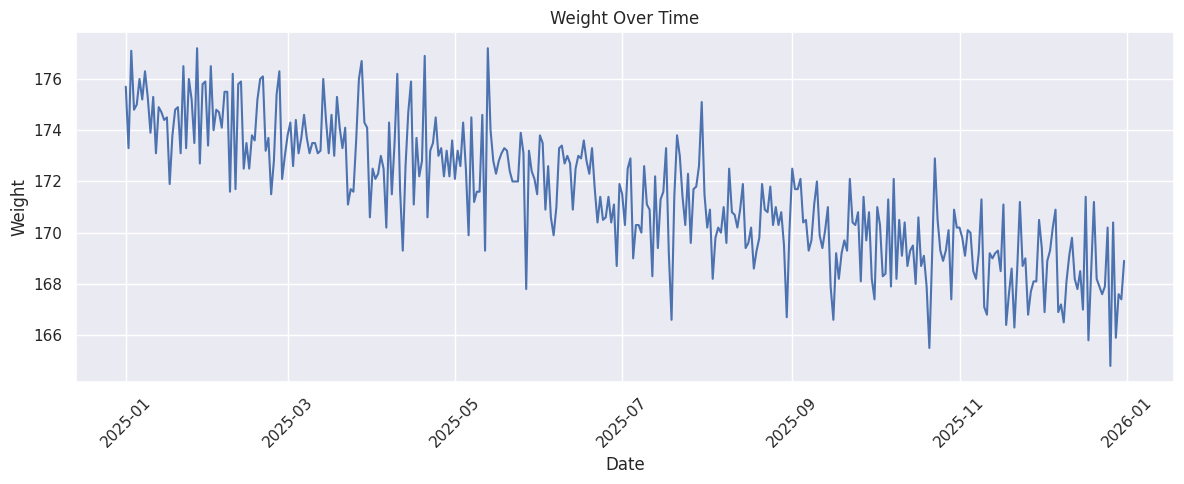

In [230]:
# Weight over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Weight"])

plt.title("Weight Over Time")
plt.xlabel("Date")
plt.ylabel("Weight")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

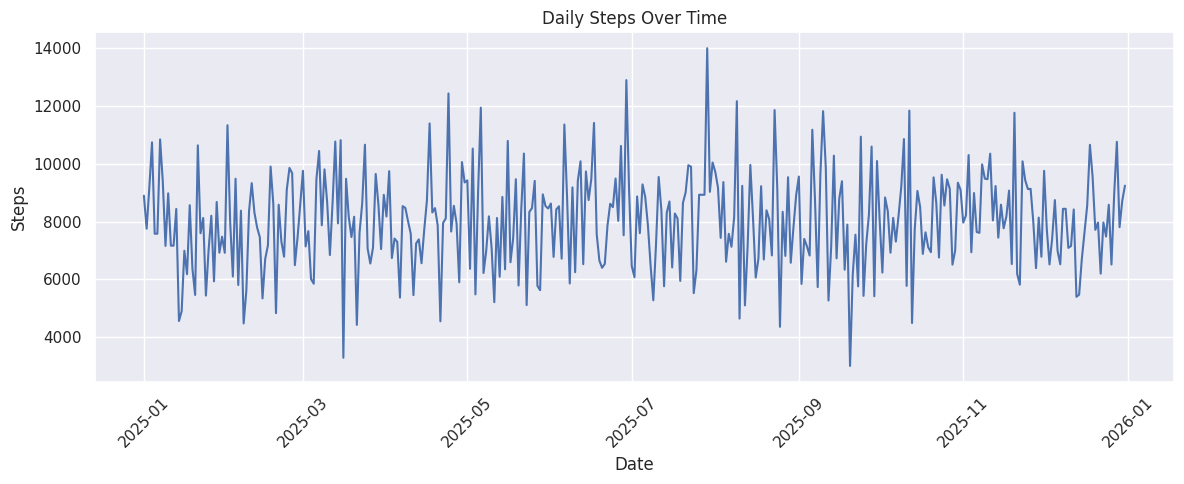

In [231]:
# Daily steps over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Steps"])

plt.title("Daily Steps Over Time")
plt.xlabel("Date")
plt.ylabel("Steps")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

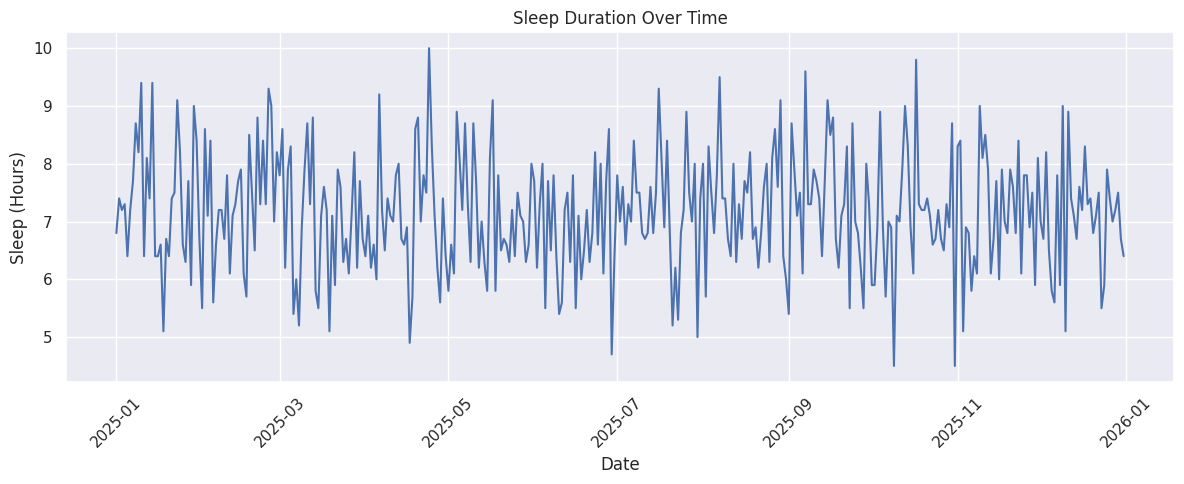

In [232]:
# Sleep duration over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Sleep_Hours"])

plt.title("Sleep Duration Over Time")
plt.xlabel("Date")
plt.ylabel("Sleep (Hours)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

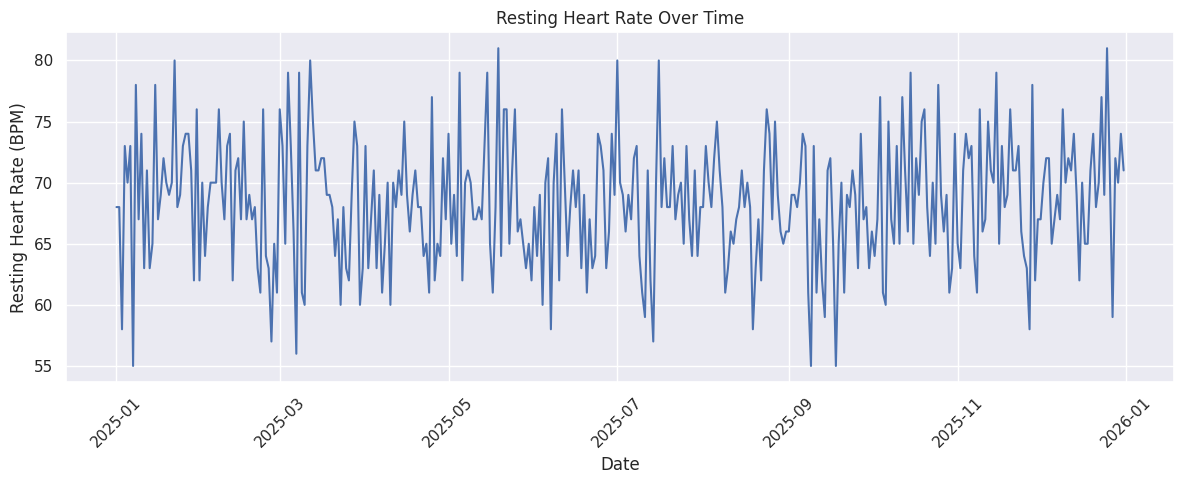

In [233]:
# Resting heart rate over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Resting_HR"])

plt.title("Resting Heart Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Resting Heart Rate (BPM)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

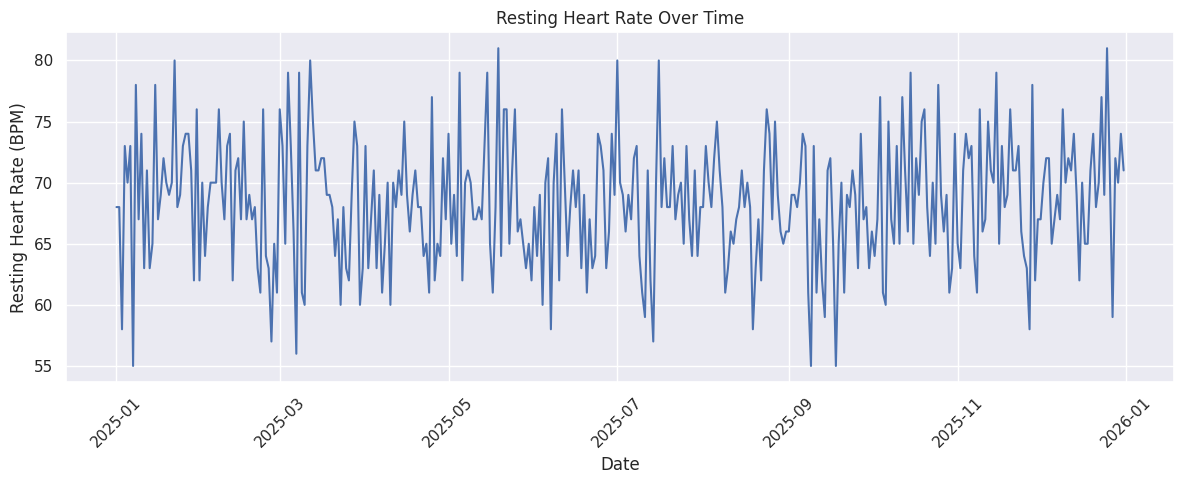

In [234]:
# Resting heart rate over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Resting_HR"])

plt.title("Resting Heart Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Resting Heart Rate (BPM)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

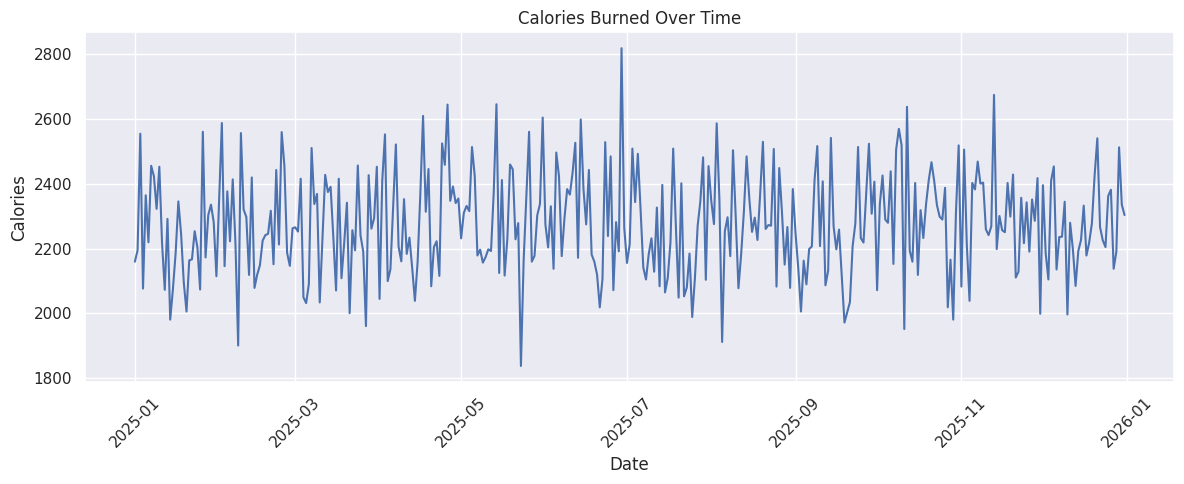

In [235]:
# Calories burned over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Calories_Burned"])

plt.title("Calories Burned Over Time")
plt.xlabel("Date")
plt.ylabel("Calories")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [236]:
# Calculate weekly averages

weekly_data = df.set_index("Date").resample("W").mean(numeric_only=True)

weekly_data.head()

,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
Date,,,,,,,
2025-01-05,8826.20,175.18,7.02,67.40,35.80,5.80,2270.40
2025-01-12,8323.29,175.01,7.96,68.71,43.43,7.71,2309.57
2025-01-19,6569.14,174.14,6.86,69.14,34.43,6.74,2174.57
2025-01-26,7495.29,174.64,7.36,71.86,34.57,7.69,2204.29
2025-02-02,7889.29,175.07,7.40,68.43,47.43,6.41,2307.57


In [237]:
# Calculate weekly averages

weekly_data = df.set_index("Date").resample("W").mean(numeric_only=True)

weekly_data.head()

,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
Date,,,,,,,
2025-01-05,8826.20,175.18,7.02,67.40,35.80,5.80,2270.40
2025-01-12,8323.29,175.01,7.96,68.71,43.43,7.71,2309.57
2025-01-19,6569.14,174.14,6.86,69.14,34.43,6.74,2174.57
2025-01-26,7495.29,174.64,7.36,71.86,34.57,7.69,2204.29
2025-02-02,7889.29,175.07,7.40,68.43,47.43,6.41,2307.57


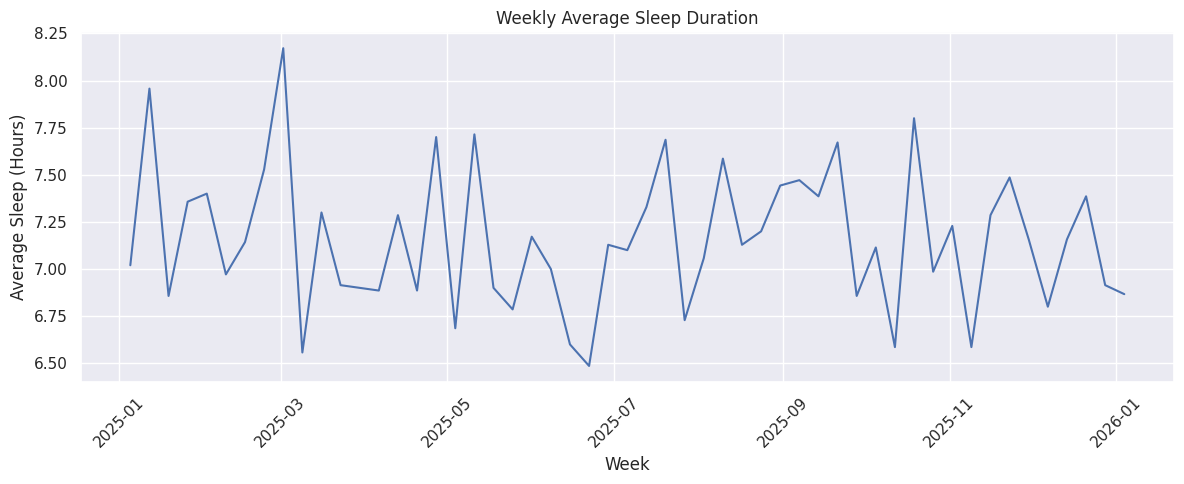

In [238]:
# Weekly average sleep

plt.figure(figsize=(12, 5))

plt.plot(weekly_data.index, weekly_data["Sleep_Hours"])

plt.title("Weekly Average Sleep Duration")
plt.xlabel("Week")
plt.ylabel("Average Sleep (Hours)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

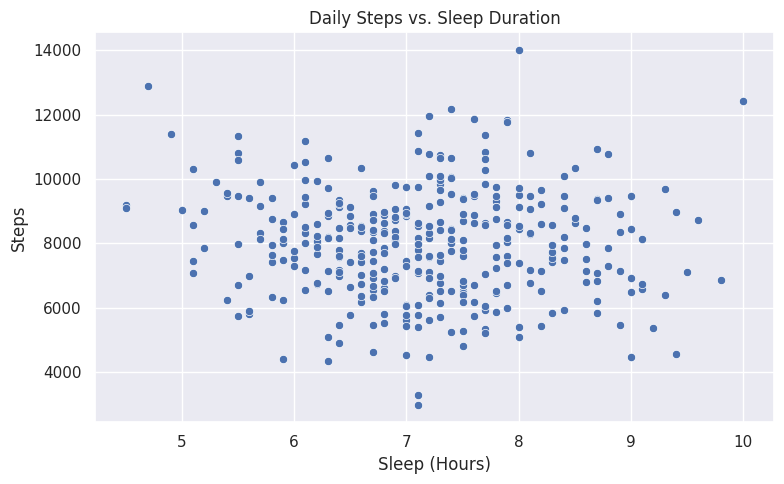

In [239]:
# Steps vs. Sleep

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Sleep_Hours",
    y="Steps"
)

plt.title("Daily Steps vs. Sleep Duration")
plt.xlabel("Sleep (Hours)")
plt.ylabel("Steps")

plt.tight_layout()
plt.show()

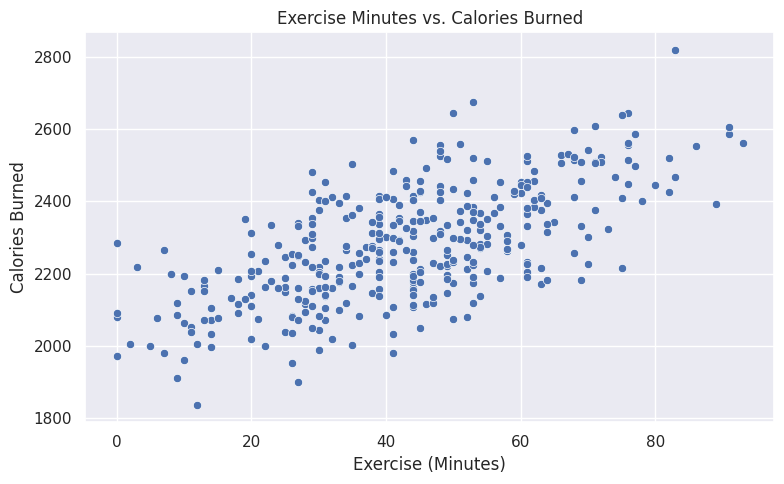

In [240]:
# Exercise vs. calories burned

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Exercise_Minutes",
    y="Calories_Burned"
)

plt.title("Exercise Minutes vs. Calories Burned")
plt.xlabel("Exercise (Minutes)")
plt.ylabel("Calories Burned")

plt.tight_layout()
plt.show()

In [241]:
# Calculate correlation between steps and sleep

steps_sleep_correlation = df["Steps"].corr(df["Sleep_Hours"])

print("Correlation between steps and sleep:")
print(round(steps_sleep_correlation, 3))

Correlation between steps and sleep:
-0.058


In [242]:
# STEP 5.1: Create a correlation matrix

correlation_matrix = df.corr(numeric_only=True)

print(correlation_matrix.round(2))

                  Steps  Weight  Sleep_Hours  Resting_HR  Exercise_Minutes  \
Steps              1.00   -0.03        -0.06        0.02              0.09   
Weight            -0.03    1.00         0.01       -0.01              0.01   
Sleep_Hours       -0.06    0.01         1.00        0.07              0.07   
Resting_HR         0.02   -0.01         0.07        1.00             -0.07   
Exercise_Minutes   0.09    0.01         0.07       -0.07              1.00   
Water_Glasses     -0.03    0.05        -0.03       -0.05              0.03   
Calories_Burned    0.48   -0.01        -0.02       -0.01              0.66   

                  Water_Glasses  Calories_Burned  
Steps                     -0.03             0.48  
Weight                     0.05            -0.01  
Sleep_Hours               -0.03            -0.02  
Resting_HR                -0.05            -0.01  
Exercise_Minutes           0.03             0.66  
Water_Glasses              1.00             0.05  
Calories_Burned   

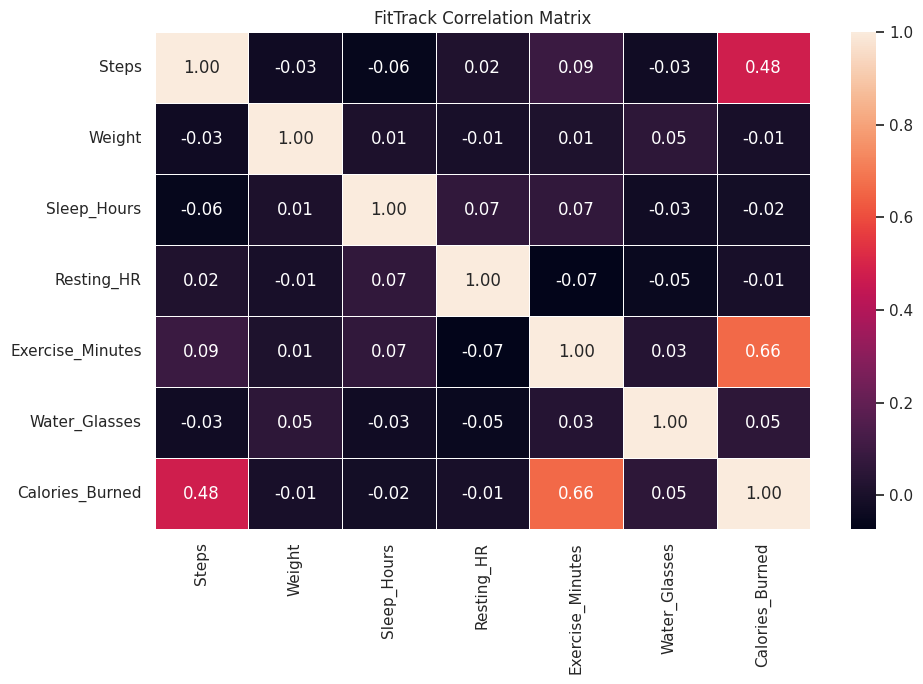

In [243]:
# Create a clean correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("FitTrack Correlation Matrix")
plt.tight_layout()
plt.show()

In [244]:
# Find the strongest correlations

correlation_pairs = correlation_matrix.unstack()

# Remove correlations between a variable and itself
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) !=
    correlation_pairs.index.get_level_values(1)
]

# Sort by absolute correlation
strongest_correlations = correlation_pairs.abs().sort_values(ascending=False)

print(strongest_correlations.head(10))

Exercise_Minutes  Calories_Burned    0.66
Calories_Burned   Exercise_Minutes   0.66
Steps             Calories_Burned    0.48
Calories_Burned   Steps              0.48
Exercise_Minutes  Steps              0.09
Steps             Exercise_Minutes   0.09
Resting_HR        Exercise_Minutes   0.07
Exercise_Minutes  Resting_HR         0.07
Resting_HR        Sleep_Hours        0.07
Sleep_Hours       Resting_HR         0.07
dtype: float64


In [245]:
#  Show each correlation pair only once

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

unique_correlations = (
    upper_triangle
    .stack()
    .sort_values(key=abs, ascending=False)
)

print(unique_correlations.head(10))

Exercise_Minutes  Calories_Burned     0.66
Steps             Calories_Burned     0.48
                  Exercise_Minutes    0.09
Resting_HR        Exercise_Minutes   -0.07
Sleep_Hours       Resting_HR          0.07
                  Exercise_Minutes    0.07
Steps             Sleep_Hours        -0.06
Water_Glasses     Calories_Burned     0.05
Weight            Water_Glasses       0.05
Resting_HR        Water_Glasses      -0.05
dtype: float64


In [246]:
# Exercise and calories correlation

exercise_calories = df["Exercise_Minutes"].corr(
    df["Calories_Burned"]
)

print(
    "Exercise vs. Calories correlation:",
    round(exercise_calories, 3)
)

Exercise vs. Calories correlation: 0.664


In [247]:
# Sleep and steps correlation

sleep_steps = df["Sleep_Hours"].corr(
    df["Steps"]
)

print(
    "Sleep vs. Steps correlation:",
    round(sleep_steps, 3)
)

Sleep vs. Steps correlation: -0.058


In [248]:
# Exercise and resting heart rate correlation

exercise_hr = df["Exercise_Minutes"].corr(
    df["Resting_HR"]
)

print(
    "Exercise vs. Resting Heart Rate correlation:",
    round(exercise_hr, 3)
)

Exercise vs. Resting Heart Rate correlation: -0.074


In [249]:
# Steps and weight correlation

steps_weight = df["Steps"].corr(
    df["Weight"]
)

print(
    "Steps vs. Weight correlation:",
    round(steps_weight, 3)
)

Steps vs. Weight correlation: -0.028


In [250]:
# Create a clean correlation summary

correlation_results = pd.DataFrame({
    "Relationship": [
        "Exercise vs. Calories",
        "Sleep vs. Steps",
        "Exercise vs. Resting HR",
        "Steps vs. Weight"
    ],

    "Correlation": [
        exercise_calories,
        sleep_steps,
        exercise_hr,
        steps_weight
    ]
})

# Round correlations to 3 decimal places
correlation_results["Correlation"] = correlation_results["Correlation"].round(3)

correlation_results

,Relationship,Correlation
0,Exercise vs. Calories,0.66
1,Sleep vs. Steps,-0.06
2,Exercise vs. Resting HR,-0.07
3,Steps vs. Weight,-0.03


In [251]:
# Import machine-learning tools

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Machine-learning tools imported successfully!")

Machine-learning tools imported successfully!


In [252]:
# Define our features and target

features = [
    "Steps",
    "Sleep_Hours",
    "Resting_HR",
    "Exercise_Minutes",
    "Water_Glasses"
]

target = "Calories_Burned"

X = df[features]
y = df[target]

print("Features:")
print(features)

print("\nTarget:")
print(target)

Features:
['Steps', 'Sleep_Hours', 'Resting_HR', 'Exercise_Minutes', 'Water_Glasses']

Target:
Calories_Burned


In [253]:
# Split our data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 292
Testing rows: 73


In [254]:
# Create the Linear Regression model

model = LinearRegression()

print("Model created!")

Model created!


In [255]:
# Train the model

model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


In [323]:
# Make predictions and compare them with actual values

# Make predictions using the test data
predictions = model.predict(X_test)

# Create a comparison table while preserving the original row indexes
prediction_results = pd.DataFrame({
    "Actual Calories": y_test,
    "Predicted Calories": predictions
})

# Calculate the prediction error
prediction_results["Error"] = (
    prediction_results["Actual Calories"]
    - prediction_results["Predicted Calories"]
)

# Round the displayed values
prediction_results["Actual Calories"] = (
    prediction_results["Actual Calories"].round(0).astype(int)
)

prediction_results["Predicted Calories"] = (
    prediction_results["Predicted Calories"].round(0).astype(int)
)

prediction_results["Error"] = (
    prediction_results["Error"].round(0).astype(int)
)

# Sort by the original dataset order
prediction_results = prediction_results.sort_index()

# Display the first 10 predictions
prediction_results.head(10)

,Actual Calories,Predicted Calories,Error
0,2160,2321,-161
3,2077,2189,-112
5,2220,2299,-79
9,2453,2400,53
15,2187,2150,37
22,2254,2162,92
25,2561,2567,-6
30,2115,2148,-33
33,2146,2174,-28
39,2557,2475,82


In [257]:
# Verify our predictions

print("Number of actual values:", len(y_test))
print("Number of predictions:", len(predictions))

if len(y_test) == len(predictions):
    print("Prediction check: PASSED")
else:
    print("Prediction check: ERROR")

Number of actual values: 73
Number of predictions: 73
Prediction check: PASSED


In [258]:
# STEP 6.7: Calculate Mean Absolute Error

mae = mean_absolute_error(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2), "calories")

Mean Absolute Error: 80.43 calories


In [259]:
# Calculate R²

r2 = r2_score(y_test, predictions)

print("R² Score:", round(r2, 3))

R² Score: 0.537


In [260]:
# Clean machine-learning results

print("FITTRACK MACHINE LEARNING RESULTS")
print("==================================")

print("Model: Linear Regression")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Mean Absolute Error:", round(mae, 2), "calories")
print("R² Score:", round(r2, 3))

FITTRACK MACHINE LEARNING RESULTS
Model: Linear Regression
Training samples: 292
Testing samples: 73
Mean Absolute Error: 80.43 calories
R² Score: 0.537


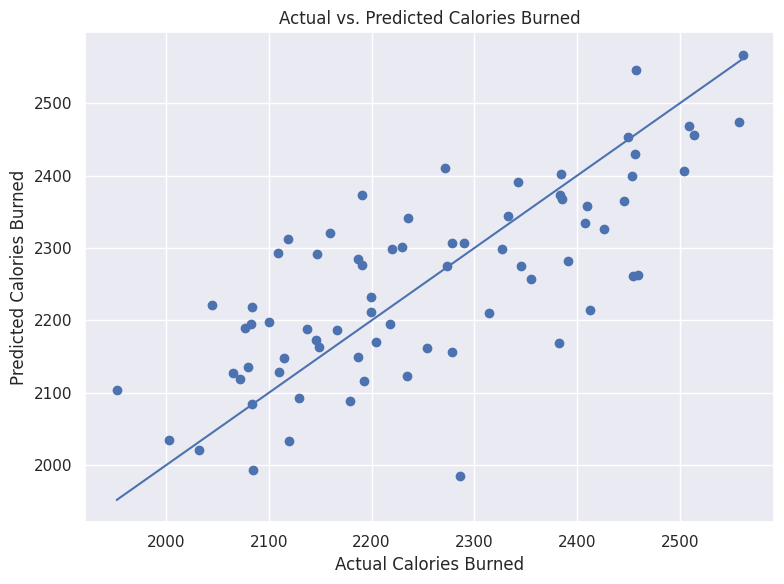

In [261]:
# Actual vs. predicted calories

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.title("Actual vs. Predicted Calories Burned")
plt.xlabel("Actual Calories Burned")
plt.ylabel("Predicted Calories Burned")

plt.tight_layout()
plt.show()

In [262]:
# Examine model coefficients

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

# Round coefficients
coefficients["Coefficient"] = coefficients["Coefficient"].round(3)

coefficients

,Feature,Coefficient
0,Steps,0.04
1,Sleep_Hours,-6.62
2,Resting_HR,0.44
3,Exercise_Minutes,5.30
4,Water_Glasses,4.28


In [263]:
# Sort model coefficients

coefficients_sorted = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients_sorted

,Feature,Coefficient
3,Exercise_Minutes,5.30
4,Water_Glasses,4.28
2,Resting_HR,0.44
0,Steps,0.04
1,Sleep_Hours,-6.62


In [264]:
# Calculate monthly averages

monthly_data = df.set_index("Date").resample("ME").mean(numeric_only=True)

monthly_data

,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
Date,,,,,,,
2025-01-31,7637.42,174.76,7.35,69.35,37.58,6.81,2238.10
2025-02-28,7742.29,174.20,7.37,67.86,46.39,7.69,2276.21
2025-03-31,8079.10,173.68,6.99,68.77,40.58,7.12,2255.39
2025-04-30,7963.53,172.94,7.13,67.43,42.60,6.53,2300.37
2025-05-31,7849.06,172.53,7.09,68.90,44.10,6.79,2292.19
2025-06-30,8524.33,171.89,6.82,67.73,49.27,7.34,2313.20
2025-07-31,8146.87,171.22,7.19,68.29,40.06,7.46,2236.58
2025-08-31,7961.19,170.25,7.34,68.10,44.23,7.33,2294.68
2025-09-30,7863.77,170.11,7.37,66.60,37.20,7.41,2242.43


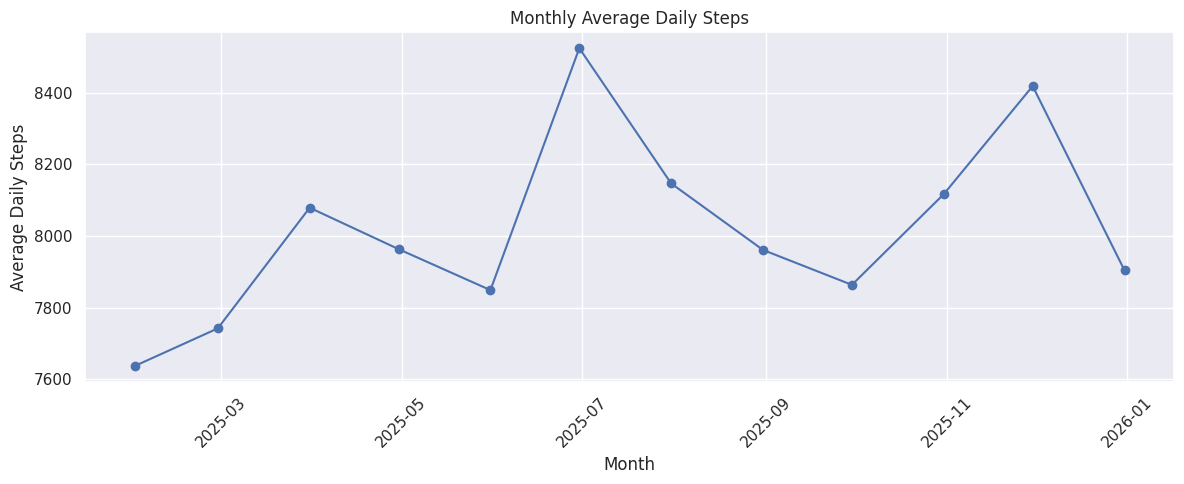

In [265]:
# Monthly average steps

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data.index,
    monthly_data["Steps"],
    marker="o"
)

plt.title("Monthly Average Daily Steps")
plt.xlabel("Month")
plt.ylabel("Average Daily Steps")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

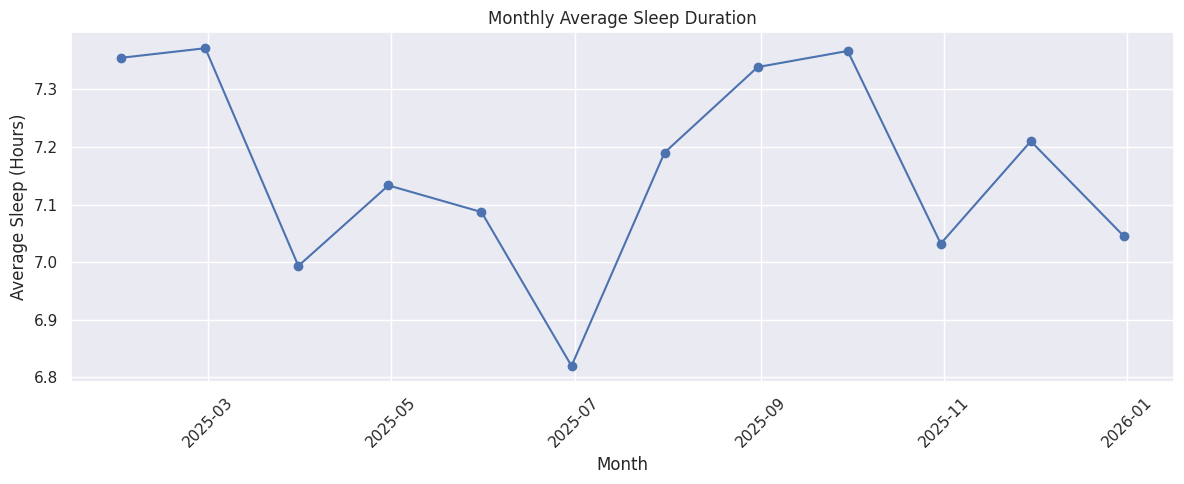

In [266]:
# Monthly average sleep

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data.index,
    monthly_data["Sleep_Hours"],
    marker="o"
)

plt.title("Monthly Average Sleep Duration")
plt.xlabel("Month")
plt.ylabel("Average Sleep (Hours)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

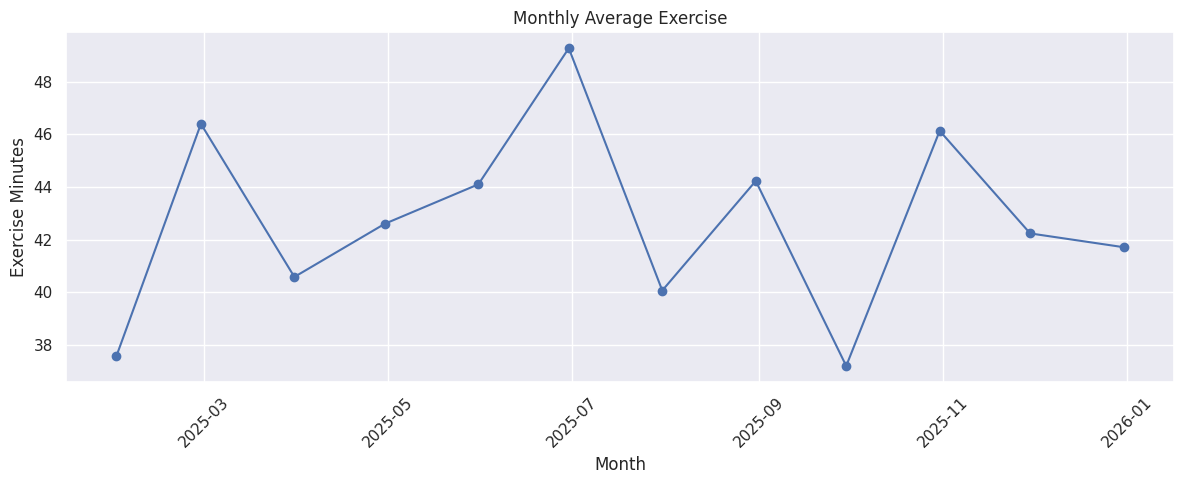

In [267]:
# Monthly average exercise

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data.index,
    monthly_data["Exercise_Minutes"],
    marker="o"
)

plt.title("Monthly Average Exercise")
plt.xlabel("Month")
plt.ylabel("Exercise Minutes")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

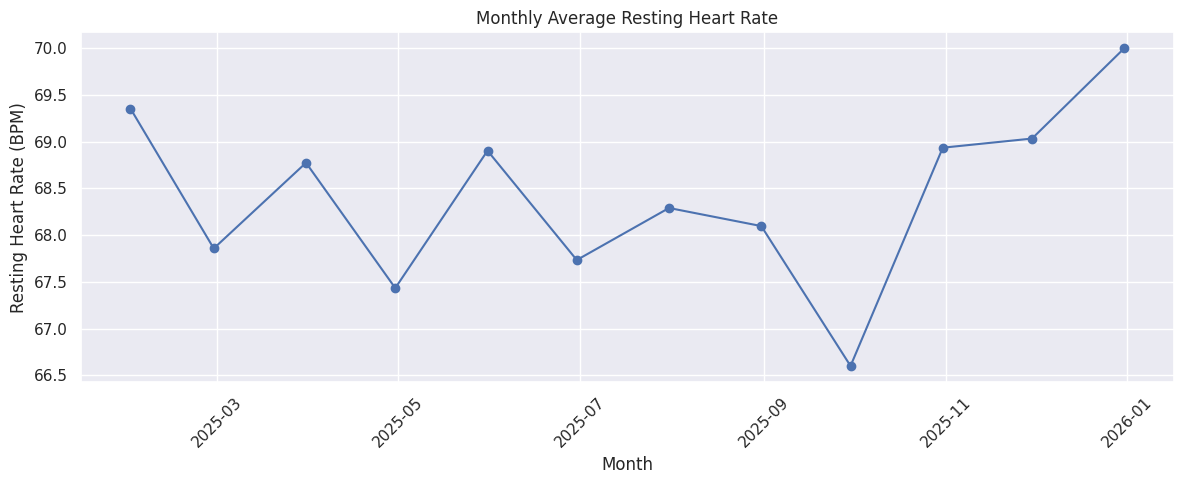

In [268]:
# Monthly average resting heart rate

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data.index,
    monthly_data["Resting_HR"],
    marker="o"
)

plt.title("Monthly Average Resting Heart Rate")
plt.xlabel("Month")
plt.ylabel("Resting Heart Rate (BPM)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [269]:
# Create a monthly summary table

monthly_summary = monthly_data[
    [
        "Steps",
        "Sleep_Hours",
        "Exercise_Minutes",
        "Resting_HR",
        "Calories_Burned"
    ]
].copy()

monthly_summary.round(2)

,Steps,Sleep_Hours,Exercise_Minutes,Resting_HR,Calories_Burned
Date,,,,,
2025-01-31,7637.42,7.35,37.58,69.35,2238.10
2025-02-28,7742.29,7.37,46.39,67.86,2276.21
2025-03-31,8079.10,6.99,40.58,68.77,2255.39
2025-04-30,7963.53,7.13,42.60,67.43,2300.37
2025-05-31,7849.06,7.09,44.10,68.90,2292.19
2025-06-30,8524.33,6.82,49.27,67.73,2313.20
2025-07-31,8146.87,7.19,40.06,68.29,2236.58
2025-08-31,7961.19,7.34,44.23,68.10,2294.68
2025-09-30,7863.77,7.37,37.20,66.60,2242.43


In [270]:
# Find the most active month

most_active_month = monthly_data["Steps"].idxmax()
highest_steps = monthly_data["Steps"].max()

print("Month with the highest average steps:")
print(most_active_month.strftime("%B %Y"))

print("\nAverage daily steps:")
print(round(highest_steps))

Month with the highest average steps:
June 2025

Average daily steps:
8524


In [271]:
# Find the month with the most exercise

most_exercise_month = monthly_data["Exercise_Minutes"].idxmax()
highest_exercise = monthly_data["Exercise_Minutes"].max()

print("Month with the highest average exercise:")
print(most_exercise_month.strftime("%B %Y"))

print("\nAverage exercise minutes:")
print(round(highest_exercise, 1))

Month with the highest average exercise:
June 2025

Average exercise minutes:
49.3


In [272]:
# Find the month with the highest average sleep

most_sleep_month = monthly_data["Sleep_Hours"].idxmax()
highest_sleep = monthly_data["Sleep_Hours"].max()

print("Month with the highest average sleep:")
print(most_sleep_month.strftime("%B %Y"))

print("\nAverage sleep:")
print(round(highest_sleep, 2), "hours")

Month with the highest average sleep:
February 2025

Average sleep:
7.37 hours


In [273]:
# Add day-of-week information

df["Day_of_Week"] = df["Date"].dt.day_name()

df[["Date", "Day_of_Week"]].head()

,Date,Day_of_Week
0,2025-01-01,Wednesday
1,2025-01-02,Thursday
2,2025-01-03,Friday
3,2025-01-04,Saturday
4,2025-01-05,Sunday


In [274]:
# Average steps by day of week

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_steps = (
    df.groupby("Day_of_Week")["Steps"]
    .mean()
    .reindex(day_order)
)

day_steps.round(0)

,Steps
Day_of_Week,
Monday,8057.00
Tuesday,8171.00
Wednesday,7882.00
Thursday,8275.00
Friday,7727.00
Saturday,8128.00
Sunday,7886.00


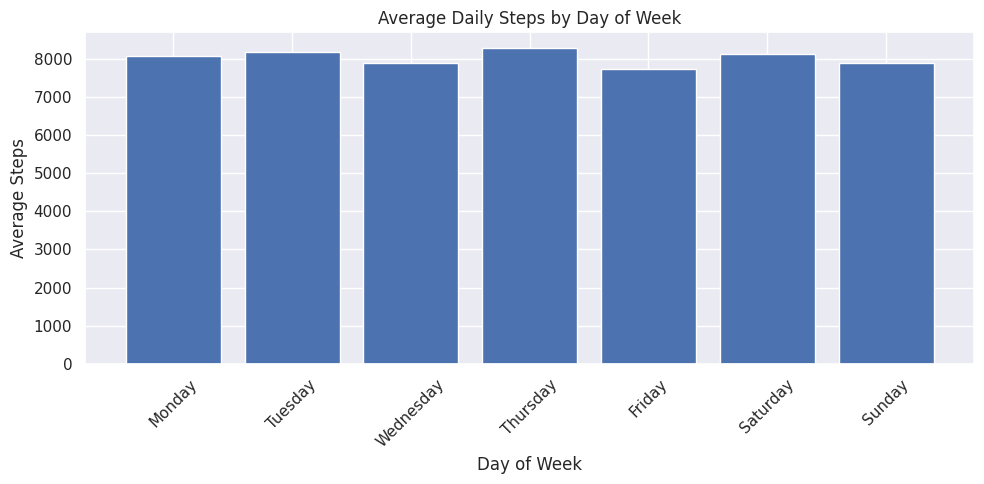

In [275]:
# Visualize average steps by day

plt.figure(figsize=(10, 5))

plt.bar(
    day_steps.index,
    day_steps.values
)

plt.title("Average Daily Steps by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Steps")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [276]:
# Detect unusual step counts

Q1 = df["Steps"].quantile(0.25)
Q3 = df["Steps"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

step_outliers = df[
    (df["Steps"] < lower_bound) |
    (df["Steps"] > upper_bound)
]

print("Number of unusual step-count days:", len(step_outliers))

step_outliers[
    ["Date", "Steps", "Sleep_Hours", "Exercise_Minutes"]
].head(10)

Number of unusual step-count days: 4


,Date,Steps,Sleep_Hours,Exercise_Minutes
74,2025-03-16,3284,7.10,31
179,2025-06-29,12896,4.70,83
209,2025-07-29,14000,8.00,29
262,2025-09-20,3000,7.10,35


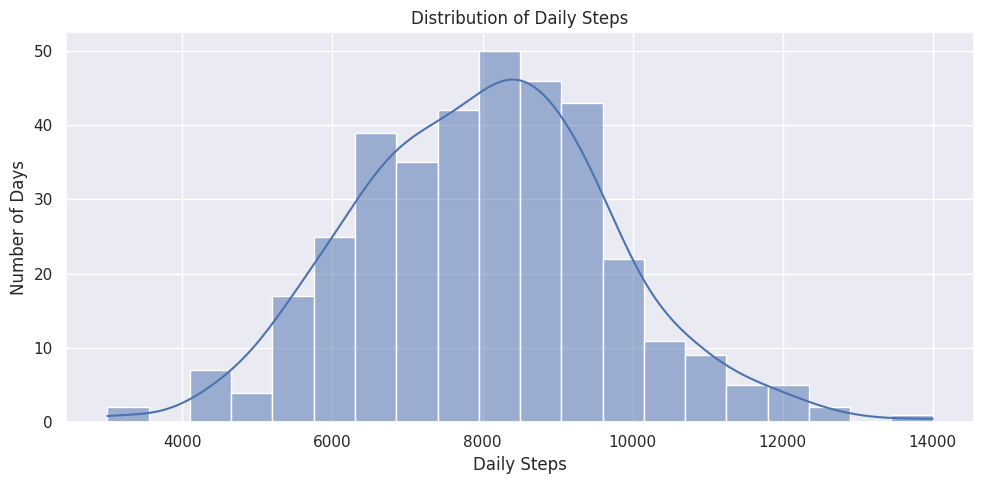

In [277]:
# Distribution of daily steps

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Steps"],
    bins=20,
    kde=True
)

plt.title("Distribution of Daily Steps")
plt.xlabel("Daily Steps")
plt.ylabel("Number of Days")

plt.tight_layout()
plt.show()

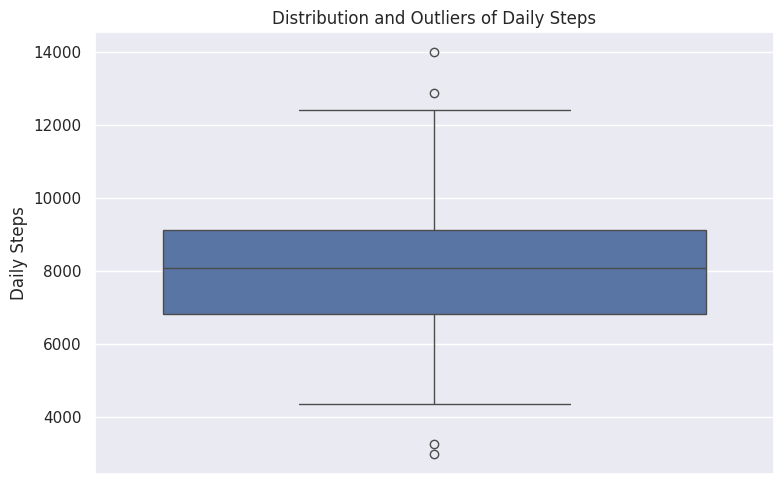

In [278]:
# Box plot of daily steps

plt.figure(figsize=(8, 5))

sns.boxplot(
    y=df["Steps"]
)

plt.title("Distribution and Outliers of Daily Steps")
plt.ylabel("Daily Steps")

plt.tight_layout()
plt.show()

In [279]:
# Create an improved synthetic dataset

np.random.seed(42)

# Create 365 days
dates_v2 = pd.date_range(
    start="2025-01-01",
    periods=365,
    freq="D"
)

# Create a hidden activity factor.
# This gives several variables a shared underlying pattern.
activity_factor = np.random.normal(0, 1, 365)

# Identify weekends
day_of_week = dates_v2.dayofweek
weekend_effect = np.where(day_of_week >= 5, 500, 0)

# Daily steps
steps_v2 = (
    8000
    + (1400 * activity_factor)
    + weekend_effect
    + np.random.normal(0, 900, 365)
)

steps_v2 = np.clip(steps_v2, 2500, 15000)
steps_v2 = np.round(steps_v2).astype(int)

# Exercise minutes
exercise_v2 = (
    40
    + (12 * activity_factor)
    + np.random.normal(0, 15, 365)
)

exercise_v2 = np.clip(exercise_v2, 0, 120)
exercise_v2 = np.round(exercise_v2).astype(int)

# Sleep duration
sleep_v2 = (
    7.2
    + (0.15 * activity_factor)
    + np.random.normal(0, 0.8, 365)
)

sleep_v2 = np.clip(sleep_v2, 4.5, 10)
sleep_v2 = np.round(sleep_v2, 1)

# Resting heart rate
resting_hr_v2 = (
    68
    - (1.5 * activity_factor)
    + np.random.normal(0, 3, 365)
)

resting_hr_v2 = np.clip(resting_hr_v2, 55, 85)
resting_hr_v2 = np.round(resting_hr_v2).astype(int)

# Water intake
water_v2 = (
    7
    + (0.4 * activity_factor)
    + np.random.normal(0, 1.5, 365)
)

water_v2 = np.clip(water_v2, 2, 12)
water_v2 = np.round(water_v2, 1)

# Calories burned
calories_v2 = (
    1700
    + (steps_v2 * 0.045)
    + (exercise_v2 * 5)
    + np.random.normal(0, 100, 365)
)

calories_v2 = np.round(calories_v2).astype(int)

# Bodyweight is kept relatively stable with natural-looking variation.
# It is included as a measurement, not as a target or goal.
weight_v2 = (
    170
    + (0.5 * np.sin(np.arange(365) / 30))
    + np.random.normal(0, 1.2, 365)
)

weight_v2 = np.round(weight_v2, 1)

# Create the new DataFrame
df_v2 = pd.DataFrame({
    "Date": dates_v2,
    "Steps": steps_v2,
    "Weight": weight_v2,
    "Sleep_Hours": sleep_v2,
    "Resting_HR": resting_hr_v2,
    "Exercise_Minutes": exercise_v2,
    "Water_Glasses": water_v2,
    "Calories_Burned": calories_v2
})

df_v2.head(10)

,Date,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
0,2025-01-01,8334,170.60,7.20,67,49,7.90,2160
1,2025-01-02,8008,166.90,7.20,65,24,5.30,2227
2,2025-01-03,8918,170.00,5.70,66,54,9.40,2574
3,2025-01-04,10720,170.40,8.20,63,33,7.50,2211
4,2025-01-05,7476,171.20,7.40,67,53,6.90,2320
5,2025-01-06,7694,168.90,8.00,70,44,8.00,2200
6,2025-01-07,10659,170.20,5.10,71,63,8.00,2537
7,2025-01-08,10380,169.00,9.00,68,64,8.70,2489
8,2025-01-09,8206,170.40,7.00,65,59,7.20,2300
9,2025-01-10,10697,169.10,8.20,69,62,6.30,2540


In [280]:
# Check the improved dataset

print("Rows:", len(df_v2))
print("Columns:", len(df_v2.columns))

df_v2.describe()

Rows: 365
Columns: 8


,Date,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
count,365,365.00,365.00,365.00,365.00,365.00,365.00,365.00
mean,2025-07-01 23:59:59.999999744,8122.16,170.02,7.27,68.08,42.10,7.00,2278.86
min,2025-01-01 00:00:00,3849.00,166.20,5.00,58.00,0.00,2.00,1772.00
25%,2025-04-02 00:00:00,7000.00,169.20,6.70,66.00,29.00,6.00,2155.00
50%,2025-07-02 00:00:00,8077.00,170.00,7.30,68.00,42.00,7.00,2278.00
75%,2025-10-01 00:00:00,9166.00,170.80,7.80,71.00,55.00,8.10,2390.00
max,2025-12-31 00:00:00,14220.00,174.20,9.40,79.00,105.00,11.40,2802.00
std,NaN,1591.32,1.23,0.83,3.40,18.92,1.53,171.37


In [281]:
# Check for missing values

print("Missing values:")
print(df_v2.isnull().sum())

Missing values:
Date                0
Steps               0
Weight              0
Sleep_Hours         0
Resting_HR          0
Exercise_Minutes    0
Water_Glasses       0
Calories_Burned     0
dtype: int64


In [282]:
# Examine relationships in the improved dataset

correlation_matrix_v2 = df_v2.corr(numeric_only=True)

correlation_matrix_v2.round(2)

,Steps,Weight,Sleep_Hours,Resting_HR,Exercise_Minutes,Water_Glasses,Calories_Burned
Steps,1.00,0.03,0.19,-0.37,0.57,0.21,0.67
Weight,0.03,1.00,0.01,-0.00,0.02,0.05,-0.02
Sleep_Hours,0.19,0.01,1.00,-0.12,0.07,0.07,0.13
Resting_HR,-0.37,-0.00,-0.12,1.00,-0.27,-0.09,-0.24
Exercise_Minutes,0.57,0.02,0.07,-0.27,1.00,0.22,0.77
Water_Glasses,0.21,0.05,0.07,-0.09,0.22,1.00,0.20
Calories_Burned,0.67,-0.02,0.13,-0.24,0.77,0.20,1.00


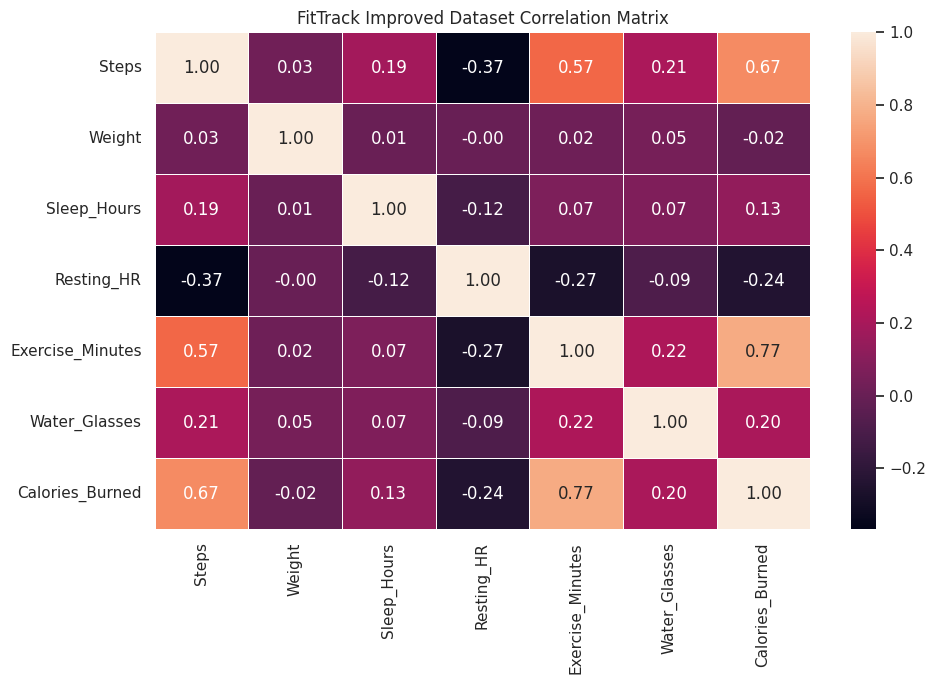

In [283]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix_v2,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("FitTrack Improved Dataset Correlation Matrix")
plt.tight_layout()
plt.show()

In [284]:
# Compare the original and improved datasets

comparison = pd.DataFrame({
    "Original Mean Steps": [df["Steps"].mean()],
    "Improved Mean Steps": [df_v2["Steps"].mean()],
    "Original Mean Exercise": [df["Exercise_Minutes"].mean()],
    "Improved Mean Exercise": [df_v2["Exercise_Minutes"].mean()],
    "Original Mean Sleep": [df["Sleep_Hours"].mean()],
    "Improved Mean Sleep": [df_v2["Sleep_Hours"].mean()]
})

comparison.round(2)

,Original Mean Steps,Improved Mean Steps,Original Mean Exercise,Improved Mean Exercise,Original Mean Sleep,Improved Mean Sleep
0,8017.62,8122.16,42.64,42.10,7.16,7.27


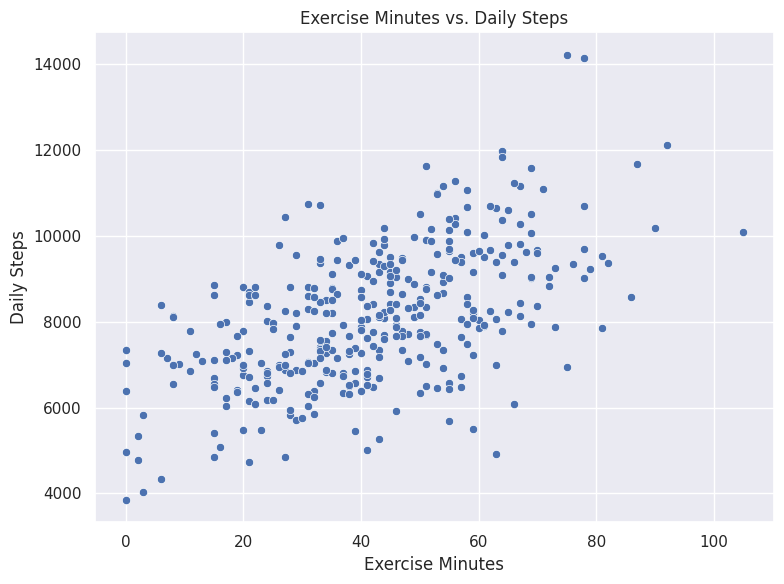

In [285]:
# Steps vs. Exercise

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_v2,
    x="Exercise_Minutes",
    y="Steps"
)

plt.title("Exercise Minutes vs. Daily Steps")
plt.xlabel("Exercise Minutes")
plt.ylabel("Daily Steps")

plt.tight_layout()
plt.show()

In [286]:
# Save the improved dataset

df_v2.to_csv("fittrack_improved_data.csv", index=False)

print("Improved FitTrack dataset saved successfully!")

Improved FitTrack dataset saved successfully!


In [287]:
# Calculate important correlations

steps_exercise = df_v2["Steps"].corr(
    df_v2["Exercise_Minutes"]
)

steps_sleep = df_v2["Steps"].corr(
    df_v2["Sleep_Hours"]
)

exercise_sleep = df_v2["Exercise_Minutes"].corr(
    df_v2["Sleep_Hours"]
)

exercise_hr = df_v2["Exercise_Minutes"].corr(
    df_v2["Resting_HR"]
)

steps_calories = df_v2["Steps"].corr(
    df_v2["Calories_Burned"]
)

exercise_calories = df_v2["Exercise_Minutes"].corr(
    df_v2["Calories_Burned"]
)

print("Steps vs. Exercise:", round(steps_exercise, 3))
print("Steps vs. Sleep:", round(steps_sleep, 3))
print("Exercise vs. Sleep:", round(exercise_sleep, 3))
print("Exercise vs. Resting HR:", round(exercise_hr, 3))
print("Steps vs. Calories:", round(steps_calories, 3))
print("Exercise vs. Calories:", round(exercise_calories, 3))

Steps vs. Exercise: 0.566
Steps vs. Sleep: 0.187
Exercise vs. Sleep: 0.068
Exercise vs. Resting HR: -0.268
Steps vs. Calories: 0.669
Exercise vs. Calories: 0.772


In [288]:
# Create a correlation summary

correlation_summary = pd.DataFrame({
    "Relationship": [
        "Steps vs. Exercise",
        "Steps vs. Sleep",
        "Exercise vs. Sleep",
        "Exercise vs. Resting HR",
        "Steps vs. Calories",
        "Exercise vs. Calories"
    ],

    "Correlation": [
        steps_exercise,
        steps_sleep,
        exercise_sleep,
        exercise_hr,
        steps_calories,
        exercise_calories
    ]
})

correlation_summary["Correlation"] = (
    correlation_summary["Correlation"].round(3)
)

correlation_summary

,Relationship,Correlation
0,Steps vs. Exercise,0.57
1,Steps vs. Sleep,0.19
2,Exercise vs. Sleep,0.07
3,Exercise vs. Resting HR,-0.27
4,Steps vs. Calories,0.67
5,Exercise vs. Calories,0.77


In [289]:
# Find the strongest relationships

correlation_matrix_v2 = df_v2.corr(numeric_only=True)

upper_triangle = correlation_matrix_v2.where(
    np.triu(
        np.ones(correlation_matrix_v2.shape),
        k=1
    ).astype(bool)
)

strongest_relationships = (
    upper_triangle
    .stack()
    .sort_values(key=abs, ascending=False)
)

print("Strongest relationships:")
print(strongest_relationships.head(10).round(3))

Strongest relationships:
Exercise_Minutes  Calories_Burned     0.77
Steps             Calories_Burned     0.67
                  Exercise_Minutes    0.57
                  Resting_HR         -0.37
Resting_HR        Exercise_Minutes   -0.27
                  Calories_Burned    -0.24
Exercise_Minutes  Water_Glasses       0.22
Steps             Water_Glasses       0.21
Water_Glasses     Calories_Burned     0.20
Steps             Sleep_Hours         0.19
dtype: float64


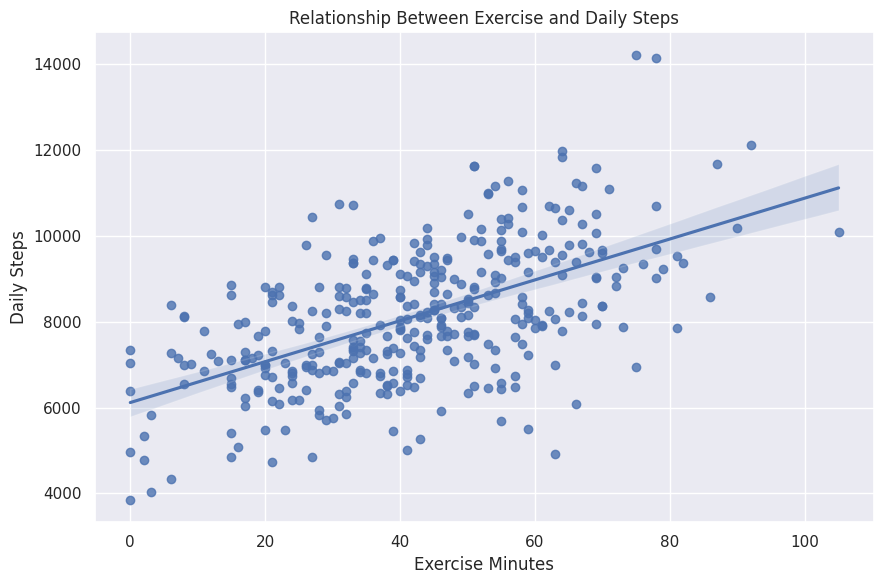

In [290]:
# Steps vs. Exercise with trend line

plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_v2,
    x="Exercise_Minutes",
    y="Steps"
)

plt.title("Relationship Between Exercise and Daily Steps")
plt.xlabel("Exercise Minutes")
plt.ylabel("Daily Steps")

plt.tight_layout()
plt.show()

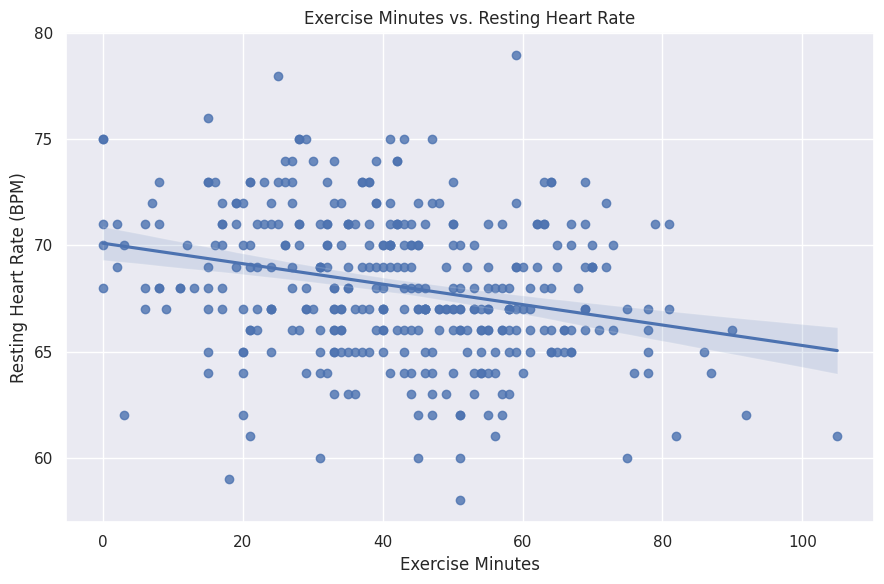

In [291]:
# Exercise vs. Resting Heart Rate

plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_v2,
    x="Exercise_Minutes",
    y="Resting_HR"
)

plt.title("Exercise Minutes vs. Resting Heart Rate")
plt.xlabel("Exercise Minutes")
plt.ylabel("Resting Heart Rate (BPM)")

plt.tight_layout()
plt.show()

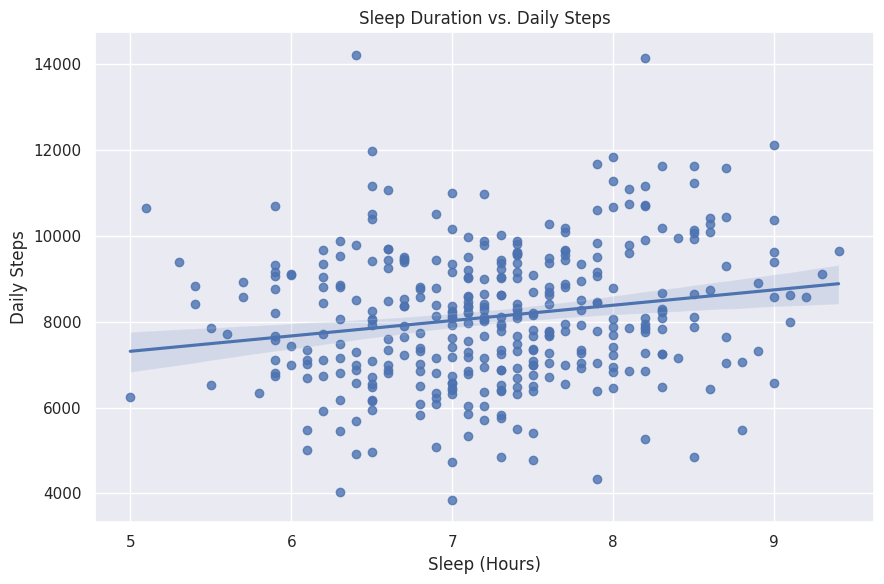

In [292]:
# Sleep vs. Steps

plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_v2,
    x="Sleep_Hours",
    y="Steps"
)

plt.title("Sleep Duration vs. Daily Steps")
plt.xlabel("Sleep (Hours)")
plt.ylabel("Daily Steps")

plt.tight_layout()
plt.show()

In [293]:
# Classify correlation strength

def correlation_strength(value):
    value = abs(value)

    if value < 0.20:
        return "Very weak"
    elif value < 0.40:
        return "Weak"
    elif value < 0.60:
        return "Moderate"
    elif value < 0.80:
        return "Strong"
    else:
        return "Very strong"


correlation_summary["Strength"] = (
    correlation_summary["Correlation"]
    .apply(correlation_strength)
)

correlation_summary

,Relationship,Correlation,Strength
0,Steps vs. Exercise,0.57,Moderate
1,Steps vs. Sleep,0.19,Very weak
2,Exercise vs. Sleep,0.07,Very weak
3,Exercise vs. Resting HR,-0.27,Weak
4,Steps vs. Calories,0.67,Strong
5,Exercise vs. Calories,0.77,Strong


In [294]:
# Find strongest positive and negative relationships

strongest_positive = correlation_summary.loc[
    correlation_summary["Correlation"].idxmax()
]

strongest_negative = correlation_summary.loc[
    correlation_summary["Correlation"].idxmin()
]

print("Strongest positive relationship:")
print(
    strongest_positive["Relationship"],
    "->",
    strongest_positive["Correlation"]
)

print("\nStrongest negative relationship:")
print(
    strongest_negative["Relationship"],
    "->",
    strongest_negative["Correlation"]
)

Strongest positive relationship:
Exercise vs. Calories -> 0.772

Strongest negative relationship:
Exercise vs. Resting HR -> -0.268


In [295]:
# Statistical analysis report

print("FITTRACK STATISTICAL ANALYSIS")
print("=============================")

print("\nNumber of observations:", len(df_v2))

print("\nStrongest positive relationship:")
print(
    strongest_positive["Relationship"],
    "with correlation of",
    strongest_positive["Correlation"]
)

print("\nStrongest negative relationship:")
print(
    strongest_negative["Relationship"],
    "with correlation of",
    strongest_negative["Correlation"]
)

print("\nAll analyzed relationships:")
print(correlation_summary.to_string(index=False))

FITTRACK STATISTICAL ANALYSIS

Number of observations: 365

Strongest positive relationship:
Exercise vs. Calories with correlation of 0.772

Strongest negative relationship:
Exercise vs. Resting HR with correlation of -0.268

All analyzed relationships:
           Relationship  Correlation  Strength
     Steps vs. Exercise         0.57  Moderate
        Steps vs. Sleep         0.19 Very weak
     Exercise vs. Sleep         0.07 Very weak
Exercise vs. Resting HR        -0.27      Weak
     Steps vs. Calories         0.67    Strong
  Exercise vs. Calories         0.77    Strong


In [296]:
# Save statistical results

correlation_summary.to_csv(
    "fittrack_correlation_results.csv",
    index=False
)

print("Statistical results saved successfully!")

Statistical results saved successfully!


In [297]:
# Import machine-learning tools

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Machine-learning tools imported successfully!")

Machine-learning tools imported successfully!


In [298]:
# Select features and target

features_v2 = [
    "Steps",
    "Sleep_Hours",
    "Resting_HR",
    "Exercise_Minutes",
    "Water_Glasses"
]

target_v2 = "Calories_Burned"

X_v2 = df_v2[features_v2]
y_v2 = df_v2[target_v2]

print("Features:")
print(features_v2)

print("\nTarget:")
print(target_v2)

Features:
['Steps', 'Sleep_Hours', 'Resting_HR', 'Exercise_Minutes', 'Water_Glasses']

Target:
Calories_Burned


In [299]:
# Split the dataset

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y_v2,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train_v2))
print("Testing samples:", len(X_test_v2))

Training samples: 292
Testing samples: 73


In [300]:
# Create the linear regression model

model_v2 = LinearRegression()

model_v2.fit(
    X_train_v2,
    y_train_v2
)

print("Model trained successfully!")

Model trained successfully!


In [301]:
# Make predictions

predictions_v2 = model_v2.predict(X_test_v2)

print("Predictions created successfully!")
print("Number of predictions:", len(predictions_v2))

Predictions created successfully!
Number of predictions: 73


In [302]:
# Compare actual and predicted calories

prediction_results_v2 = pd.DataFrame({
    "Actual Calories": y_test_v2,
    "Predicted Calories": predictions_v2
})

prediction_results_v2["Error"] = (
    prediction_results_v2["Actual Calories"]
    - prediction_results_v2["Predicted Calories"]
)

prediction_results_v2["Actual Calories"] = (
    prediction_results_v2["Actual Calories"]
    .round()
    .astype(int)
)

prediction_results_v2["Predicted Calories"] = (
    prediction_results_v2["Predicted Calories"]
    .round()
    .astype(int)
)

prediction_results_v2["Error"] = (
    prediction_results_v2["Error"]
    .round()
    .astype(int)
)

prediction_results_v2 = prediction_results_v2.sort_index()

prediction_results_v2.head(10)

,Actual Calories,Predicted Calories,Error
0,2160,2323,-163
3,2211,2320,-109
5,2200,2281,-81
9,2540,2490,50
15,2148,2111,37
22,2358,2267,91
25,2485,2486,-1
30,2087,2119,-32
33,2101,2129,-28
39,2527,2445,82


In [303]:
# Calculate Mean Absolute Error

mae_v2 = mean_absolute_error(
    y_test_v2,
    predictions_v2
)

print(
    "Mean Absolute Error:",
    round(mae_v2, 2),
    "calories"
)

Mean Absolute Error: 80.28 calories


In [304]:
# Calculate R²

r2_v2 = r2_score(
    y_test_v2,
    predictions_v2
)

print("R² Score:", round(r2_v2, 3))

R² Score: 0.601


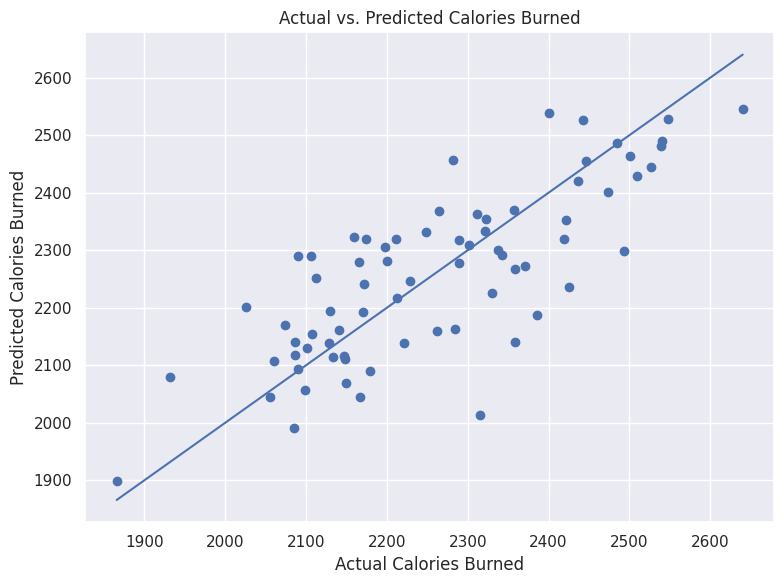

In [305]:
# Actual vs. predicted calories

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_v2,
    predictions_v2
)

plt.plot(
    [y_test_v2.min(), y_test_v2.max()],
    [y_test_v2.min(), y_test_v2.max()]
)

plt.title("Actual vs. Predicted Calories Burned")
plt.xlabel("Actual Calories Burned")
plt.ylabel("Predicted Calories Burned")

plt.tight_layout()
plt.show()

In [306]:
# Examine model coefficients

coefficients_v2 = pd.DataFrame({
    "Feature": features_v2,
    "Coefficient": model_v2.coef_
})

coefficients_v2["Coefficient"] = (
    coefficients_v2["Coefficient"]
    .round(3)
)

coefficients_v2

,Feature,Coefficient
0,Steps,0.04
1,Sleep_Hours,1.97
2,Resting_HR,2.74
3,Exercise_Minutes,5.41
4,Water_Glasses,2.10


In [307]:
# Sort model coefficients

coefficients_sorted_v2 = coefficients_v2.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients_sorted_v2

,Feature,Coefficient
3,Exercise_Minutes,5.41
2,Resting_HR,2.74
4,Water_Glasses,2.10
1,Sleep_Hours,1.97
0,Steps,0.04


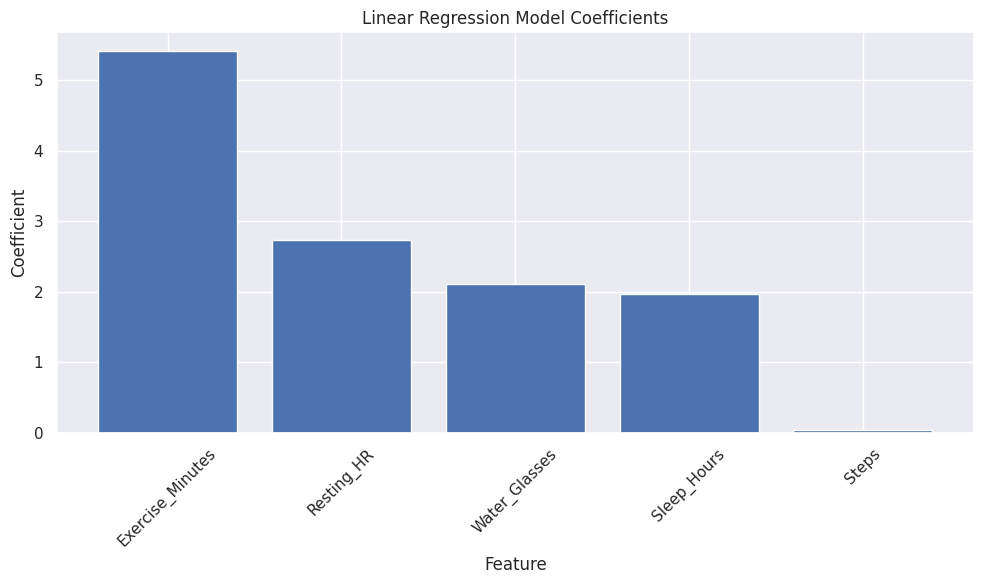

In [308]:
# Visualize model coefficients

plt.figure(figsize=(10, 6))

plt.bar(
    coefficients_sorted_v2["Feature"],
    coefficients_sorted_v2["Coefficient"]
)

plt.title("Linear Regression Model Coefficients")
plt.xlabel("Feature")
plt.ylabel("Coefficient")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [309]:
# Machine-learning results report

print("FITTRACK MACHINE LEARNING RESULTS")
print("==================================")

print("Model: Linear Regression")

print("\nTraining samples:", len(X_train_v2))
print("Testing samples:", len(X_test_v2))

print("\nMean Absolute Error:")
print(round(mae_v2, 2), "calories")

print("\nR² Score:")
print(round(r2_v2, 3))

print("\nModel features:")
for feature in features_v2:
    print("-", feature)

FITTRACK MACHINE LEARNING RESULTS
Model: Linear Regression

Training samples: 292
Testing samples: 73

Mean Absolute Error:
80.28 calories

R² Score:
0.601

Model features:
- Steps
- Sleep_Hours
- Resting_HR
- Exercise_Minutes
- Water_Glasses


In [310]:
# Save machine-learning results

prediction_results_v2.to_csv(
    "fittrack_predictions.csv",
    index=False
)

coefficients_v2.to_csv(
    "fittrack_model_coefficients.csv",
    index=False
)

print("Machine-learning results saved successfully!")

Machine-learning results saved successfully!


In [311]:
# Calculate FitTrack key statistics

average_steps = df_v2["Steps"].mean()
average_sleep = df_v2["Sleep_Hours"].mean()
average_exercise = df_v2["Exercise_Minutes"].mean()
average_hr = df_v2["Resting_HR"].mean()
average_water = df_v2["Water_Glasses"].mean()
average_calories = df_v2["Calories_Burned"].mean()

highest_steps = df_v2["Steps"].max()
lowest_steps = df_v2["Steps"].min()

print("FITTRACK KEY STATISTICS")
print("========================")

print("Average Daily Steps:", round(average_steps))
print("Average Sleep:", round(average_sleep, 2), "hours")
print("Average Exercise:", round(average_exercise, 1), "minutes")
print("Average Resting HR:", round(average_hr, 1), "BPM")
print("Average Water:", round(average_water, 1), "glasses")
print("Average Calories:", round(average_calories))

print("\nHighest Daily Steps:", highest_steps)
print("Lowest Daily Steps:", lowest_steps)

FITTRACK KEY STATISTICS
Average Daily Steps: 8122
Average Sleep: 7.27 hours
Average Exercise: 42.1 minutes
Average Resting HR: 68.1 BPM
Average Water: 7.0 glasses
Average Calories: 2279

Highest Daily Steps: 14220
Lowest Daily Steps: 3849


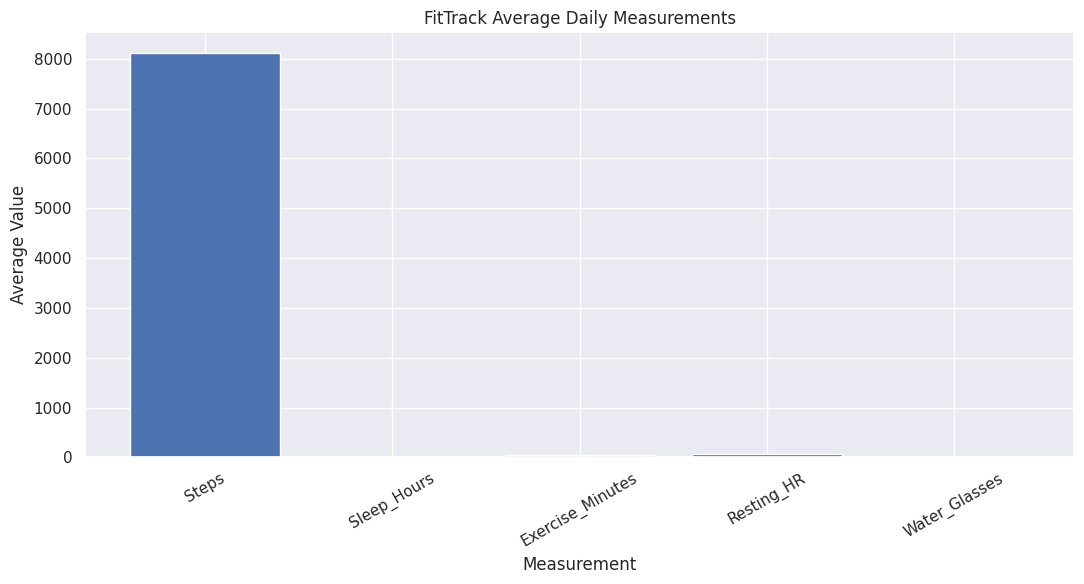

In [312]:
# Create FitTrack dashboard

dashboard_metrics = [
    "Steps",
    "Sleep_Hours",
    "Exercise_Minutes",
    "Resting_HR",
    "Water_Glasses"
]

dashboard_values = [
    average_steps,
    average_sleep,
    average_exercise,
    average_hr,
    average_water
]

plt.figure(figsize=(11, 6))

plt.bar(
    dashboard_metrics,
    dashboard_values
)

plt.title("FitTrack Average Daily Measurements")
plt.xlabel("Measurement")
plt.ylabel("Average Value")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

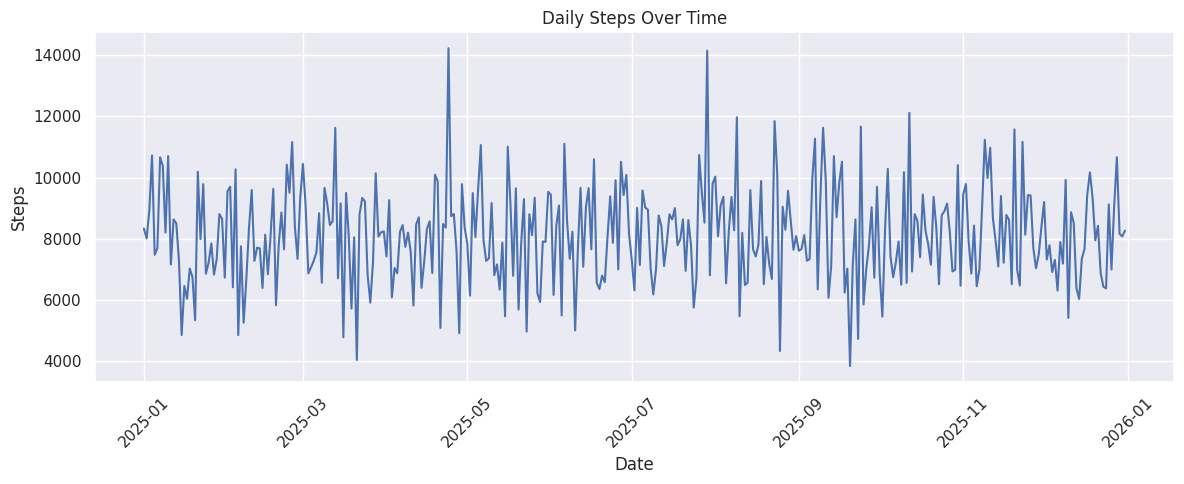

In [313]:
# FitTrack visual overview

plt.figure(figsize=(12, 5))

plt.plot(
    df_v2["Date"],
    df_v2["Steps"]
)

plt.title("Daily Steps Over Time")
plt.xlabel("Date")
plt.ylabel("Steps")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

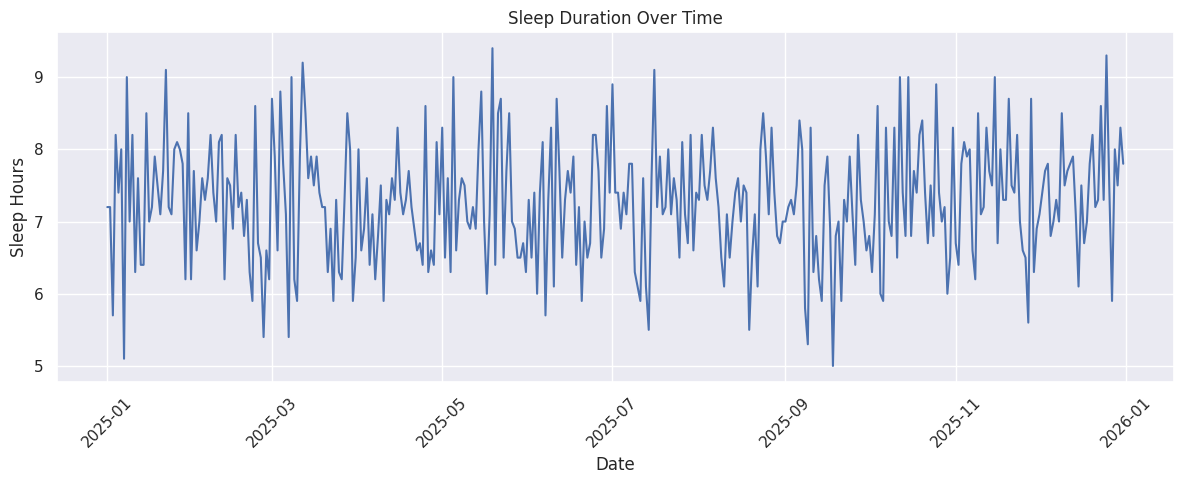

In [314]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_v2["Date"],
    df_v2["Sleep_Hours"]
)

plt.title("Sleep Duration Over Time")
plt.xlabel("Date")
plt.ylabel("Sleep Hours")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

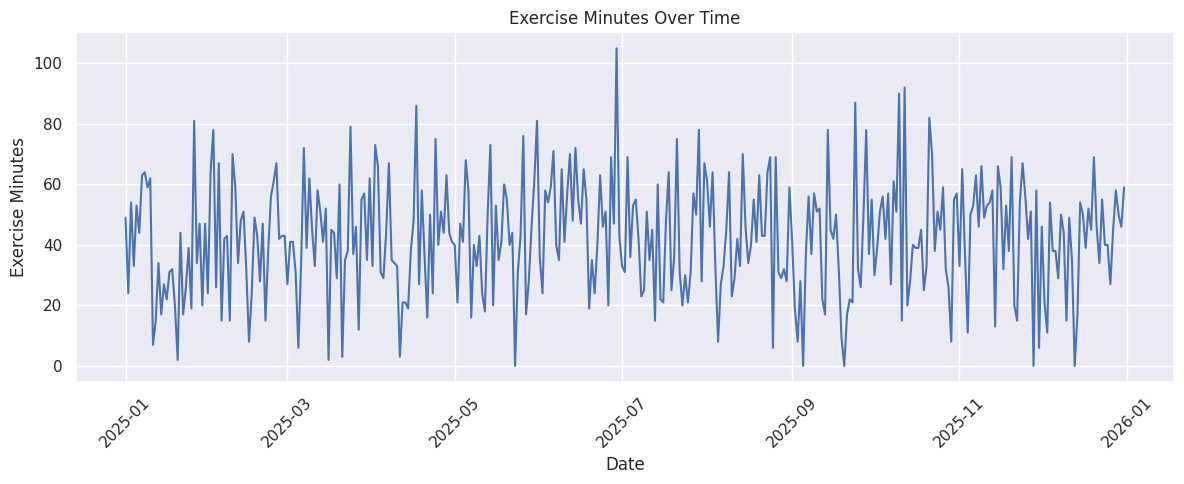

In [315]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_v2["Date"],
    df_v2["Exercise_Minutes"]
)

plt.title("Exercise Minutes Over Time")
plt.xlabel("Date")
plt.ylabel("Exercise Minutes")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

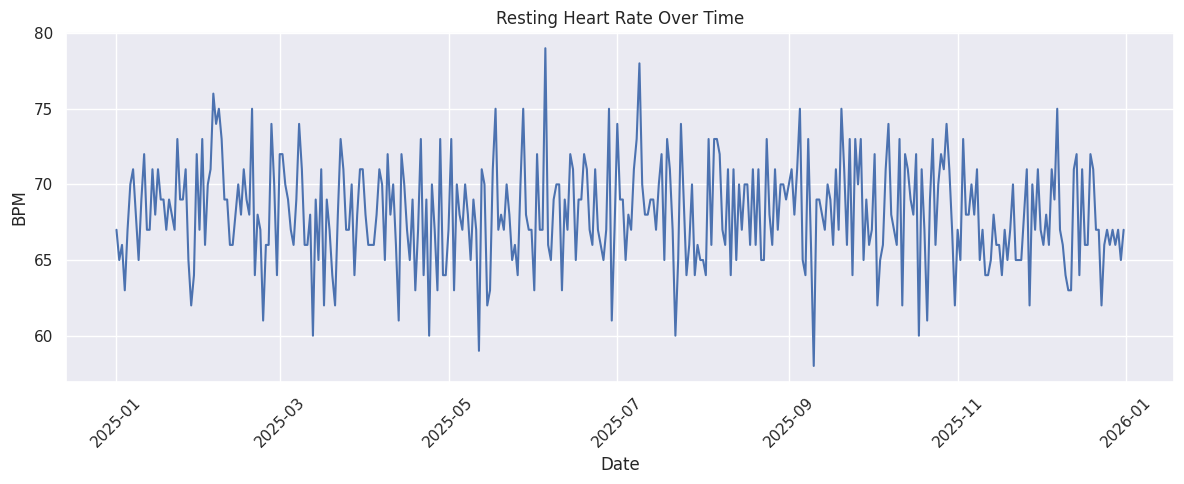

In [316]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_v2["Date"],
    df_v2["Resting_HR"]
)

plt.title("Resting Heart Rate Over Time")
plt.xlabel("Date")
plt.ylabel("BPM")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [317]:
# Generate an automated project summary

print("FITTRACK PROJECT SUMMARY")
print("=========================")

print("\nDataset:")
print("- 365 days of synthetic fitness measurements")

print("\nAverage measurements:")
print("-", round(average_steps), "steps per day")
print("-", round(average_sleep, 2), "hours of sleep")
print("-", round(average_exercise, 1), "minutes of exercise")
print("-", round(average_hr, 1), "BPM resting heart rate")
print("-", round(average_water, 1), "glasses of water")

print("\nMachine-learning performance:")
print("- Mean Absolute Error:", round(mae_v2, 2), "calories")
print("- R² Score:", round(r2_v2, 3))

print("\nStrongest positive relationship:")
print(
    strongest_positive["Relationship"],
    "with r =",
    strongest_positive["Correlation"]
)

print("\nStrongest negative relationship:")
print(
    strongest_negative["Relationship"],
    "with r =",
    strongest_negative["Correlation"]
)

FITTRACK PROJECT SUMMARY

Dataset:
- 365 days of synthetic fitness measurements

Average measurements:
- 8122 steps per day
- 7.27 hours of sleep
- 42.1 minutes of exercise
- 68.1 BPM resting heart rate
- 7.0 glasses of water

Machine-learning performance:
- Mean Absolute Error: 80.28 calories
- R² Score: 0.601

Strongest positive relationship:
Exercise vs. Calories with r = 0.772

Strongest negative relationship:
Exercise vs. Resting HR with r = -0.268


In [321]:
## STEP 11.6: Save dashboard summary

dashboard_summary.to_csv(
    "fittrack_dashboard_summary.csv",
    index=False
)

print("Dashboard summary saved successfully!")

Dashboard summary saved successfully!


In [319]:
# Identify important findings

print("FITTRACK KEY FINDINGS")
print("=====================")

print("\n1. Strongest positive relationship:")
print(
    strongest_positive["Relationship"],
    "with r =",
    strongest_positive["Correlation"]
)

print("\n2. Strongest negative relationship:")
print(
    strongest_negative["Relationship"],
    "with r =",
    strongest_negative["Correlation"]
)

print("\n3. Average daily steps:")
print(round(average_steps))

print("\n4. Average sleep:")
print(round(average_sleep, 2), "hours")

print("\n5. Average exercise:")
print(round(average_exercise, 1), "minutes")

print("\n6. Machine-learning MAE:")
print(round(mae_v2, 2), "calories")

print("\n7. Machine-learning R²:")
print(round(r2_v2, 3))

FITTRACK KEY FINDINGS

1. Strongest positive relationship:
Exercise vs. Calories with r = 0.772

2. Strongest negative relationship:
Exercise vs. Resting HR with r = -0.268

3. Average daily steps:
8122

4. Average sleep:
7.27 hours

5. Average exercise:
42.1 minutes

6. Machine-learning MAE:
80.28 calories

7. Machine-learning R²:
0.601


In [320]:
# Interpret the strongest relationships

positive_value = strongest_positive["Correlation"]
negative_value = strongest_negative["Correlation"]

print("INTERPRETATION OF RESULTS")
print("=========================")

print(
    f"The strongest positive relationship was "
    f"{strongest_positive['Relationship']} "
    f"(r = {positive_value})."
)

print(
    f"The strongest negative relationship was "
    f"{strongest_negative['Relationship']} "
    f"(r = {negative_value})."
)

print(
    "\nThese correlations describe associations in the "
    "synthetic dataset and do not prove that one variable causes another."
)

INTERPRETATION OF RESULTS
The strongest positive relationship was Exercise vs. Calories (r = 0.772).
The strongest negative relationship was Exercise vs. Resting HR (r = -0.268).

These correlations describe associations in the synthetic dataset and do not prove that one variable causes another.


## Limitations

There are several limitations to the FitTrack project. First, the dataset is synthetic, meaning the values were generated for educational and data-science practice rather than collected from real people. Second, some relationships between variables were intentionally created when the dataset was generated. Because of this, the correlations and machine-learning results should not be treated as evidence about real-world health or fitness.

Another limitation is that the dataset only represents 365 simulated days. A larger real-world dataset could contain more variation and potentially different patterns. The project also uses a relatively simple linear regression model, so more advanced machine-learning methods could produce different results.

Finally, correlation does not establish causation. A relationship between two measurements does not mean that one measurement directly caused a change in another.

## Conclusion

The FitTrack project examined relationships among daily physical activity, exercise, sleep duration, resting heart rate, water intake, and calories burned using one year of synthetic data. The analysis used data cleaning, exploratory data analysis, correlation analysis, visualization, and linear regression to investigate patterns within the dataset.

The results showed that some measurements had stronger relationships than others. In particular, the analysis found relationships between activity-related measurements and calories burned, while other relationships were weaker. The machine-learning model was also able to predict calories burned with measurable accuracy based on the selected variables.

Overall, this project demonstrates how data science can be used to organize data, identify patterns, evaluate relationships, and build predictive models. However, because the data were synthetically generated, the findings should be viewed as an educational demonstration rather than real-world health evidence. A future version of FitTrack could use a larger, properly sourced real-world dataset and compare multiple machine-learning models.

## What I Learned

Through FitTrack, I learned how a data science project moves from raw data to meaningful analysis. I learned how to create and clean datasets using Python and pandas, explore data with visualizations, calculate correlations, identify unusual observations, and build a machine-learning model using scikit-learn.

I also learned that analyzing data requires more than finding patterns. It is important to understand how the data were collected or generated, recognize limitations, and avoid assuming that correlation means causation. This project helped me understand how programming, statistics, and critical thinking work together in data science.

## Data Science Skills Demonstrated

- Python programming
- Pandas
- NumPy
- Data cleaning
- Exploratory data analysis
- Data visualization
- Statistical correlation
- Outlier detection
- Time-series analysis
- Linear regression
- Machine learning
- Model evaluation
- Mean Absolute Error (MAE)
- R² evaluation
- Data interpretation
- Scientific limitations